# 0. Paper Figures & Tables Guide (`Recovering a Taxonomy of Collective Behaviors from Motion Alone`)

This notebook rebuilds **every publication figure** of the paper (main text + appendices) using the exact verified pipeline caches in `results/epuck/paper/`, displays them inline, and summarizes what to read in each plot.

> **Interactive walkthroughs:** If you want step-by-step mathematical intuition, synthetic toy swarms, and code explanations rather than just regenerating paper plots, follow notebooks **01 → 07** in order!

In [1]:
import pickle, subprocess, sys
from pathlib import Path
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name in ("analysis", "notebooks") else Path.cwd()
sys.path[:0] = [str(ROOT / "analysis"), str(ROOT / "src"), str(ROOT)]

import numpy as np
import make_figures as M
import illustrations as I
import figlib as L

FIG = ROOT / "figures"

def show(name, width=900):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

## 1. Pipeline Overview & Missions (Figures 1 & 3)

* **Figure 1 (`fig_method`)** — End-to-end flow on the robot data: Shelter exemplar tracks → 5 closed-form fields at $\sigma_3$ → grid-free alpha complex → extended persistence diagrams → 20 distance matrices → 4 moment-balanced views $W_m$ → SNF consensus $S^\star$ → $C=5$ exemplars + differentiable attribution back to the robots.
* **Figure 3 (`fig_missions`)** — Top-down view of the five e-puck missions (`120 s` or `180 s`, `20` robots in a `4.91 m^2` dodecagonal arena), with exemplar trajectories.

saved thumbnails
thumb_tracks       exists = True
thumb_fields       exists = True
thumb_diagram      exists = True
thumb_distance     exists = True
thumb_consensus    exists = True
thumb_exemplars    exists = True


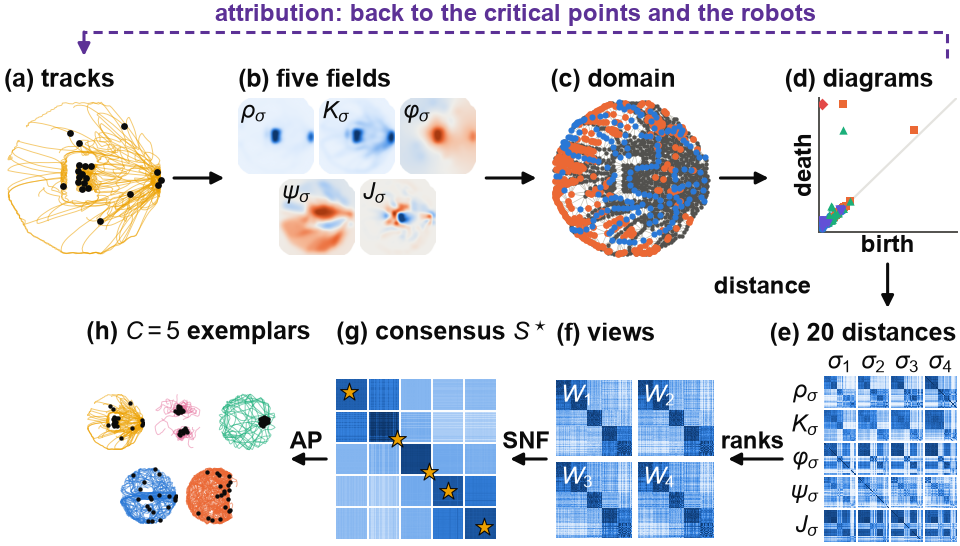

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_missions.pdf


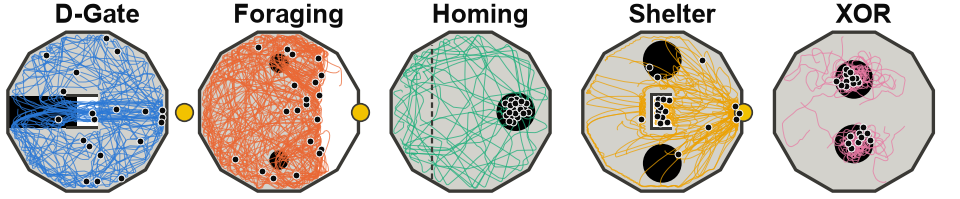

In [2]:
M.fig_thumbs()
for name in ("thumb_tracks", "thumb_fields", "thumb_diagram", "thumb_distance", "thumb_consensus", "thumb_exemplars"):
    print(f"{name:18s} exists = {(FIG / f'{name}.pdf').exists()}")
show("fig_method", 900)
M.fig_missions(); show("fig_missions", 900)

## 2. Synthetic Method Illustrations (Figures 2 & 11–14)

* **Figure 11 (`fig_footprint`, Appendix)** — Gaussian footprint of width $\sigma$: $5\sigma$ evaluation window (`exp(-12.5)` tail omitted) and the $d \le 2.35\,\sigma$ merging threshold.
* **Figure 12 (`fig_moments`, Appendix)** — Why all three velocity moments ($M_0, \mathbf{M}_1, \operatorname{tr} M_2$) matter: two crossing streams cancel in net flux $\mathbf{M}_1$ yet add up in kinetic intensity $K_\sigma$.
* **Figure 13 (`fig_flows`, Appendix)** — Closed-form Helmholtz–Hodge potentials on sink, source, and counterclockwise vortex flows.
* **Figure 2 (`fig_potentials`, Main Text)** — Why the **Jacobi coupling** $J_\sigma = \sigma^2 \det(\nabla\varphi_\sigma, \nabla\psi_\sigma)$ is needed: coinciding sink + vortex leaves $J_\sigma \approx 0$, whereas separating them lights up $J_\sigma$ between them.
* **Figure 14 (`fig_persistence`, Appendix)** — Sublevel sets growing across a scalar field into birth–death persistence pairs and sliced Wasserstein projections.

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_footprint.pdf


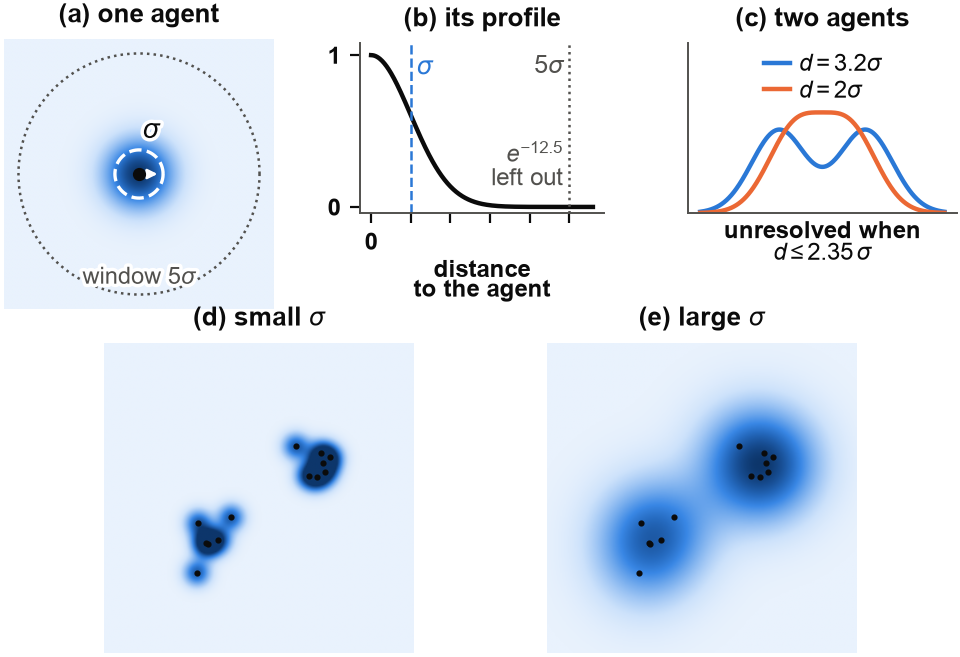

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_moments.pdf


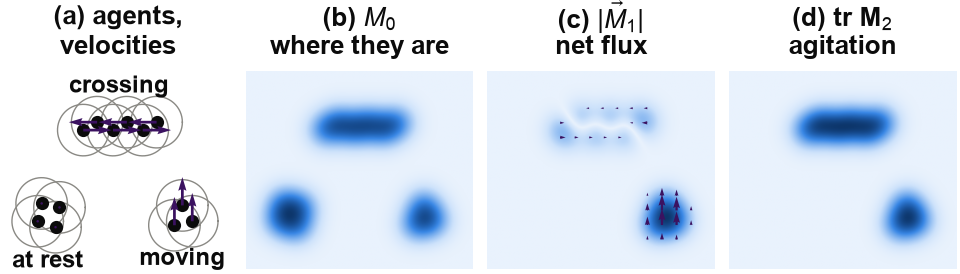

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_persistence.pdf


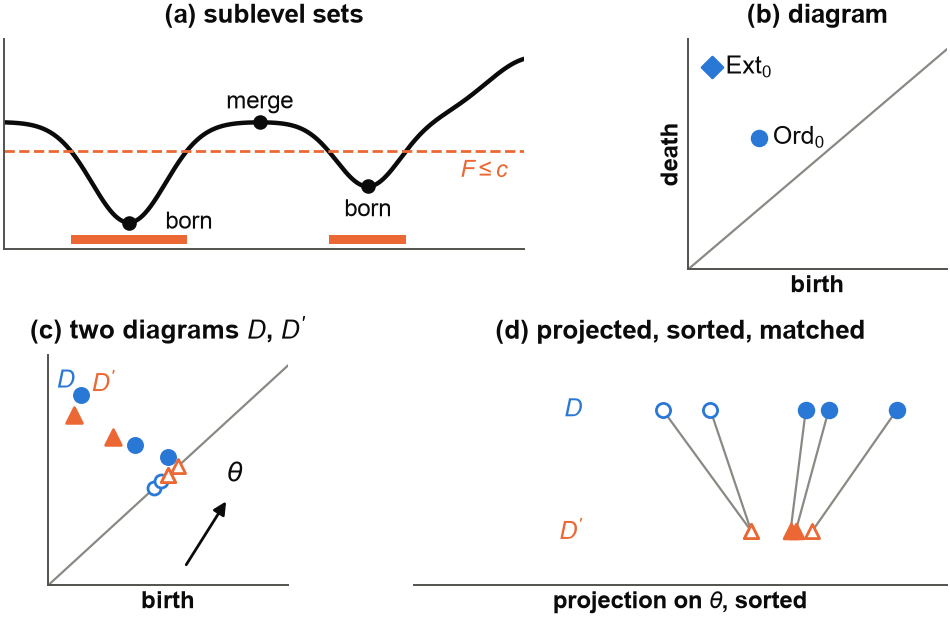

In [3]:
I.fig_footprint(); show("fig_footprint", 820)
I.fig_moments(); show("fig_moments", 820)
I.fig_persistence(); show("fig_persistence", 820)

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_flows.pdf


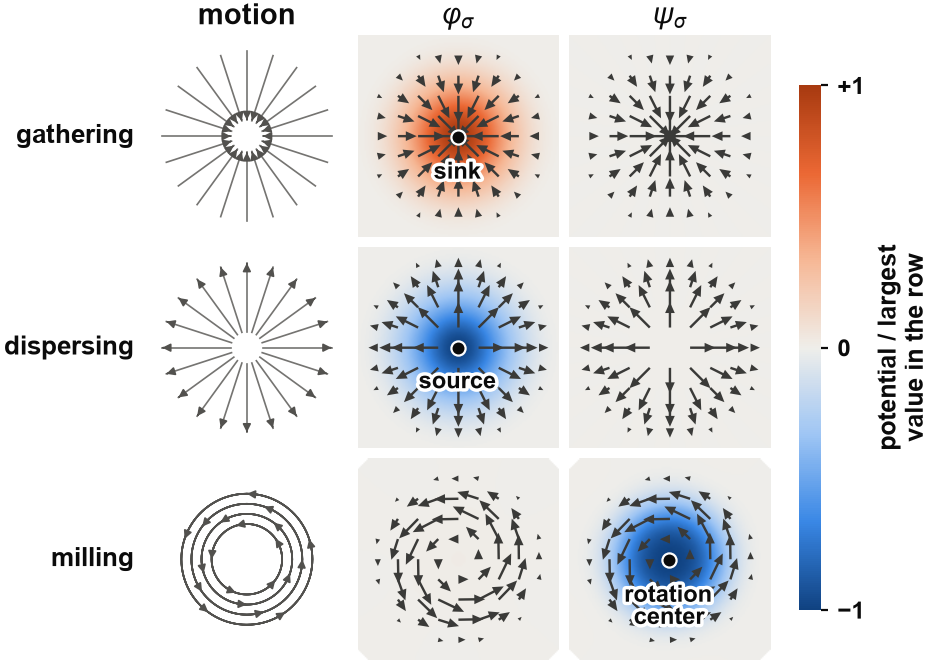

In [4]:
I.fig_flows(); show("fig_flows", 820)

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_potentials.pdf


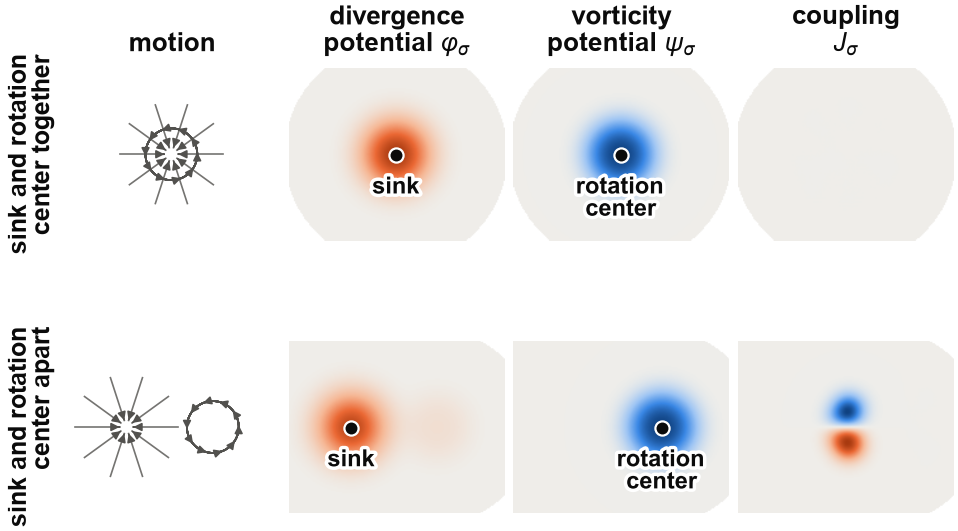

In [5]:
I.fig_potentials(); show("fig_potentials", 820)

## 3. Resolution Maps, Stable States & Transition Scaling (Figures 4, 6 & 7)

* **Figure 4 (`fig_states`)** — Global proportional window across `Top-1..Top-10` ($k_{\mathrm{nn}} \in [3, 50n],\ t \in [1, 50]$): nested stable states bounded by crisp transition lines.
* **Figure 6 (`fig_resolution_map`)** — Zoomed local resolution grid ($9 \times 11 = 99$ settings) for all ten datasets: `C* = 5` (`84/99`) on Top-1 (`0` misassigned runs), growing to `C* = 11` sub-behaviors (`1.000` purity) on Top-10.
* **Figure 7 (`fig_law`)** — Power-law scaling $k_{\mathrm{nn}}/n = 131\,t^{-0.55}$ on Top-2..Top-7 vs steepening exponents on Top-8..Top-10 caused by atypical controllers (`10th` Shelter moving like traffic, `10th` XOR moving like Shelter).

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_states.pdf


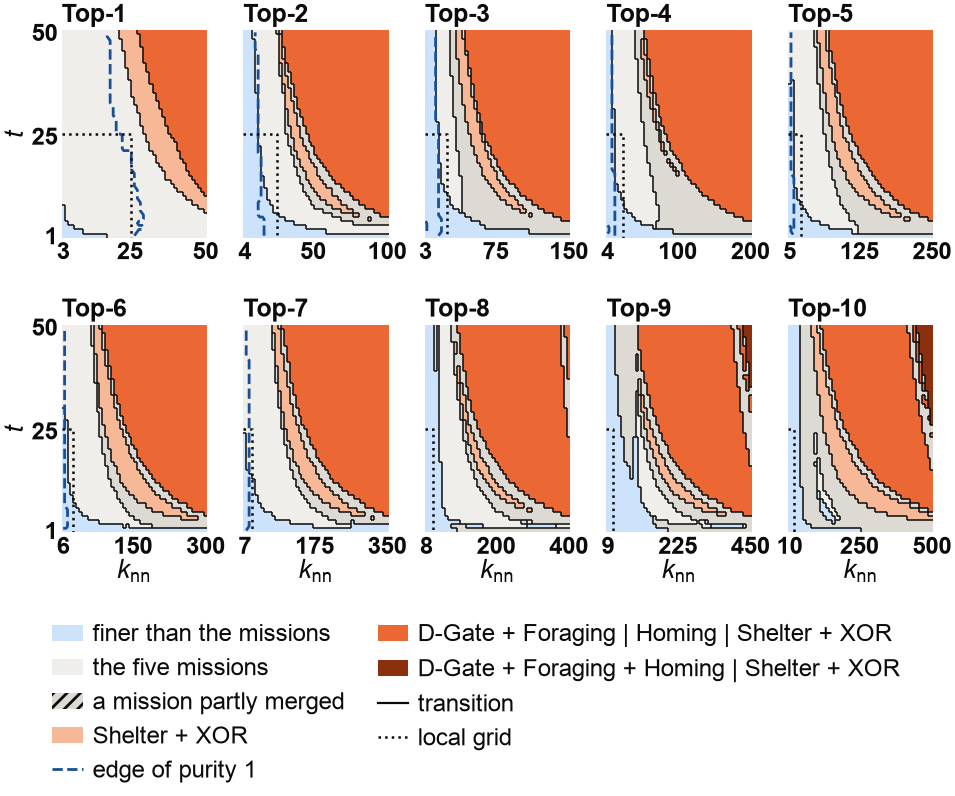

In [6]:
M.fig_states(); show("fig_states", 880)

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_resolution_map.pdf
WARNING fig_resolution_map: 60 texts below 8.5 pt on the page (scale 0.902): '$C^\\star\\!=\\!11$ (17/99)' 7.7 pt, '$C^\\star\\!=\\!11$ (18/99)' 7.7 pt, '$C^\\star\\!=\\!11$ (19/99)' 7.7 pt, '$C^\\star\\!=\\!5$ (84/99)' 7.7 pt, '$C^\\star\\!=\\!6$ (33/99)' 7.7 pt, '$C^\\star\\!=\\!7$ (32/99)' 7.7 pt ...
        content outside the canvas, inches: left 0.000, right 0.000


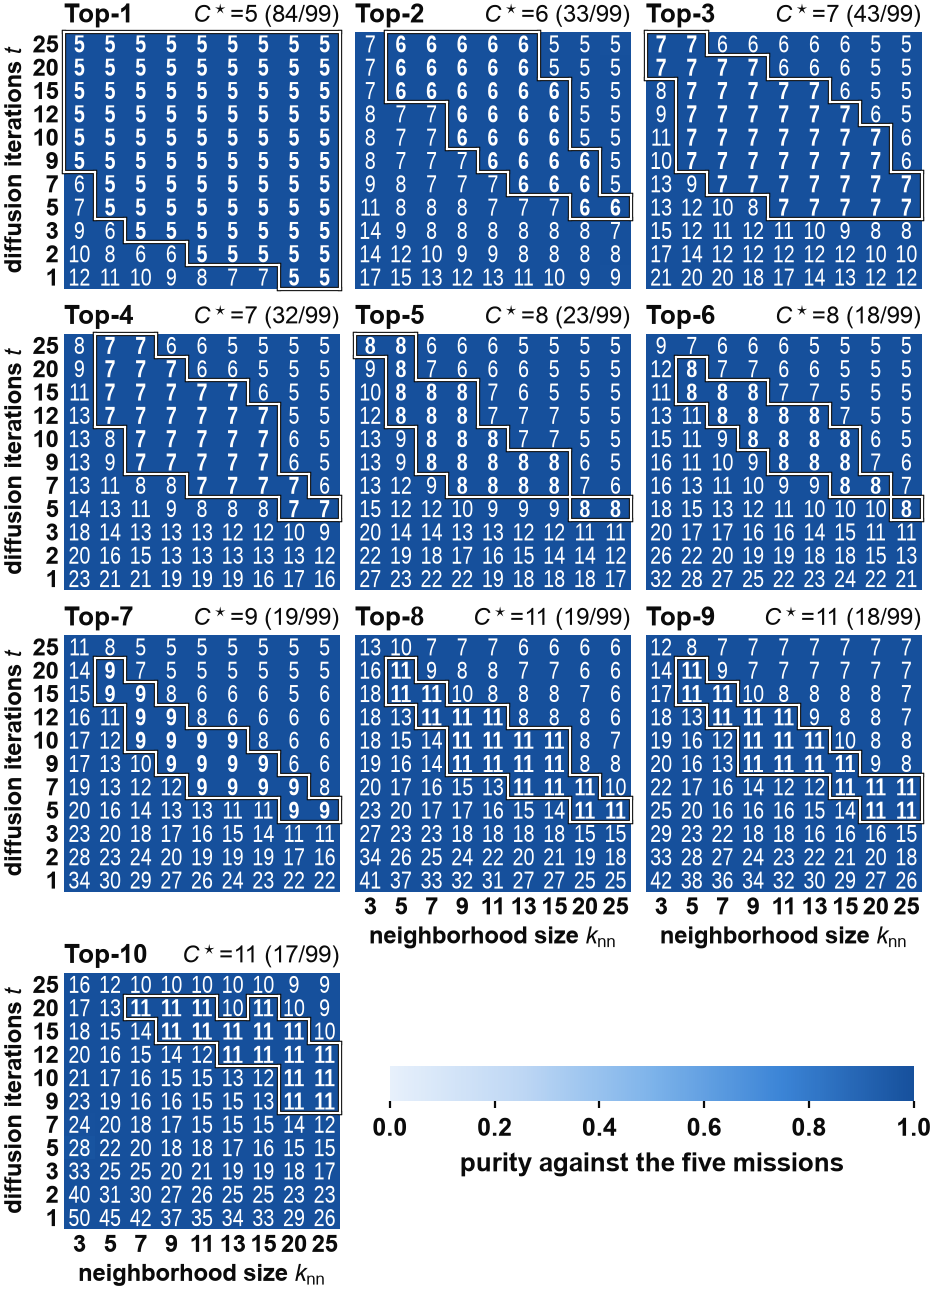

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_law.pdf


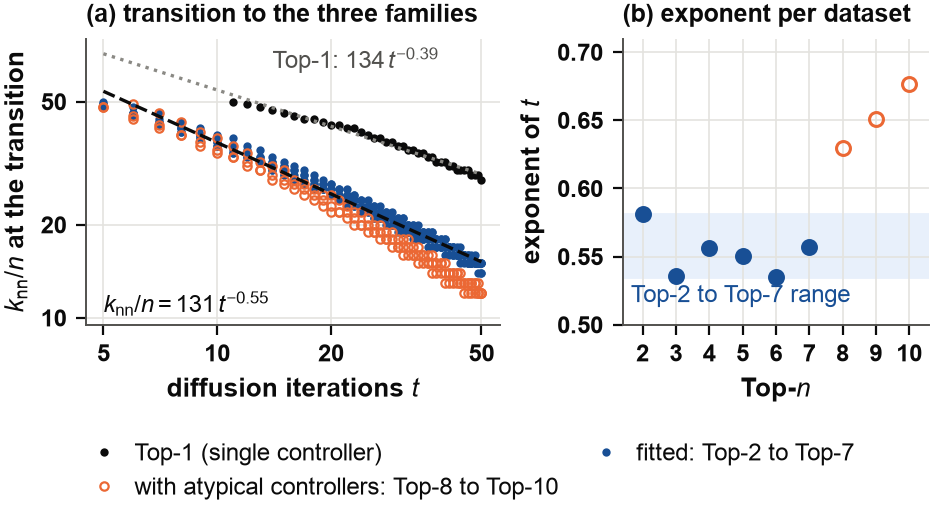

In [7]:
M.fig_resolution(); show("fig_resolution_map", 750)
M.fig_law(); show("fig_law", 850)

## 4. Taxonomy Summary Table (`taxonomy.pkl` / Table 1)

In [8]:
T = pickle.load(open(ROOT / "results/epuck/paper/taxonomy.pkl", "rb"))
print(f"{'Dataset':>7} {'C*':>3} {'Modal':>8} {'Stab':>6} {'Purity':>7} {'Wrong':>6} {'Hom':>6} {'Comp':>6} {'ARI':>6}")
print("-" * 64)
for top, t in T.items():
    print(f"Top-{top:<2}  {t['C']:>3} {t['n_plateau']:>4}/99  {t['stability']:6.3f} {t['purity']:7.3f} "
          f"{t['misassigned']:>5}  {t['homogeneity']:6.3f} {t['completeness']:6.3f} {t['ari']:6.3f}")

Dataset  C*    Modal   Stab  Purity  Wrong    Hom   Comp    ARI
----------------------------------------------------------------
Top-1     5   84/99   1.000   1.000     0   1.000  1.000  1.000
Top-2     6   33/99   0.994   1.000     0   1.000  0.921  0.935
Top-3     7   43/99   0.993   1.000     0   1.000  0.860  0.875
Top-4     7   32/99   0.992   1.000     0   1.000  0.872  0.893
Top-5     8   23/99   0.988   1.000     0   1.000  0.838  0.868
Top-6     8   18/99   0.990   0.999     1   0.997  0.836  0.870
Top-7     9   19/99   0.979   1.000     0   1.000  0.806  0.837
Top-8    11   19/99   0.976   0.999     2   0.997  0.747  0.766
Top-9    11   18/99   0.968   0.999     2   0.997  0.724  0.720
Top-10   11   17/99   0.981   1.000     1   0.999  0.745  0.762


## 5. Pairwise Field Separation & Five Fields of Top-1 Exemplars (Figures 5 & 8)

* **Figure 5 (`fig_pair_separation`)** — Between/within distance ratio for all 10 mission pairs across all 5 fields: **vorticity $\psi_\sigma$ (`3.35`)** separates *D-Gate / Foraging* best; **divergence $\varphi_\sigma$ (`3.34`)** separates *Shelter / XOR* best; **kinetic intensity $K_\sigma$ (`6.49`, `4.68`)** separates *Homing* from aggregation missions; **density $\rho_\sigma$** and **$J_\sigma$** complement the rest.
* **Figure 8 (`fig_fields`)** — Tracks alongside all five closed-form fields at $\sigma_3 = 7.18\text{ cm}$ for each discovered Top-1 exemplar.

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_pair_separation.pdf


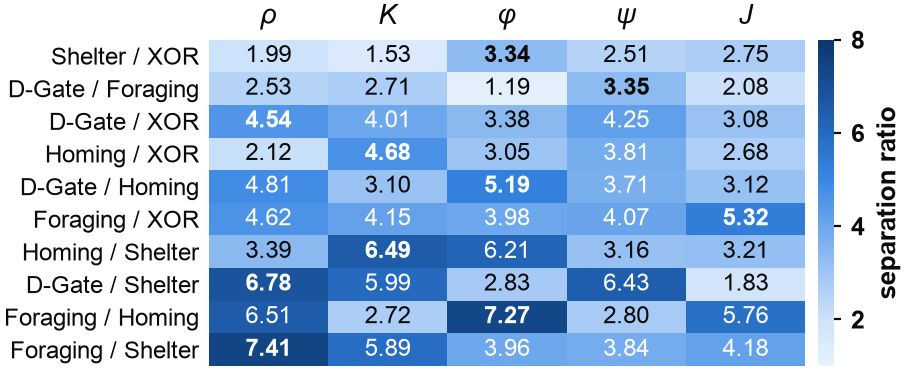

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_fields.pdf
WARNING fig_fields: 11 texts below 8.5 pt on the page (scale 0.766): 'Jacobi\ncoupling\n$J_\\sigma$' 7.7 pt, 'density\n\n$\\rho_\\sigma$' 7.7 pt, 'divergence\npotential\n$\\varphi_\\sigma$' 7.7 pt, 'kinetic\nintensity\n$K_\\sigma$' 7.7 pt, 'tracks\n\n' 7.7 pt, 'vorticity\npotential\n$\\psi_\\sigma$' 7.7 pt ...
        content outside the canvas, inches: left 0.000, right 0.000


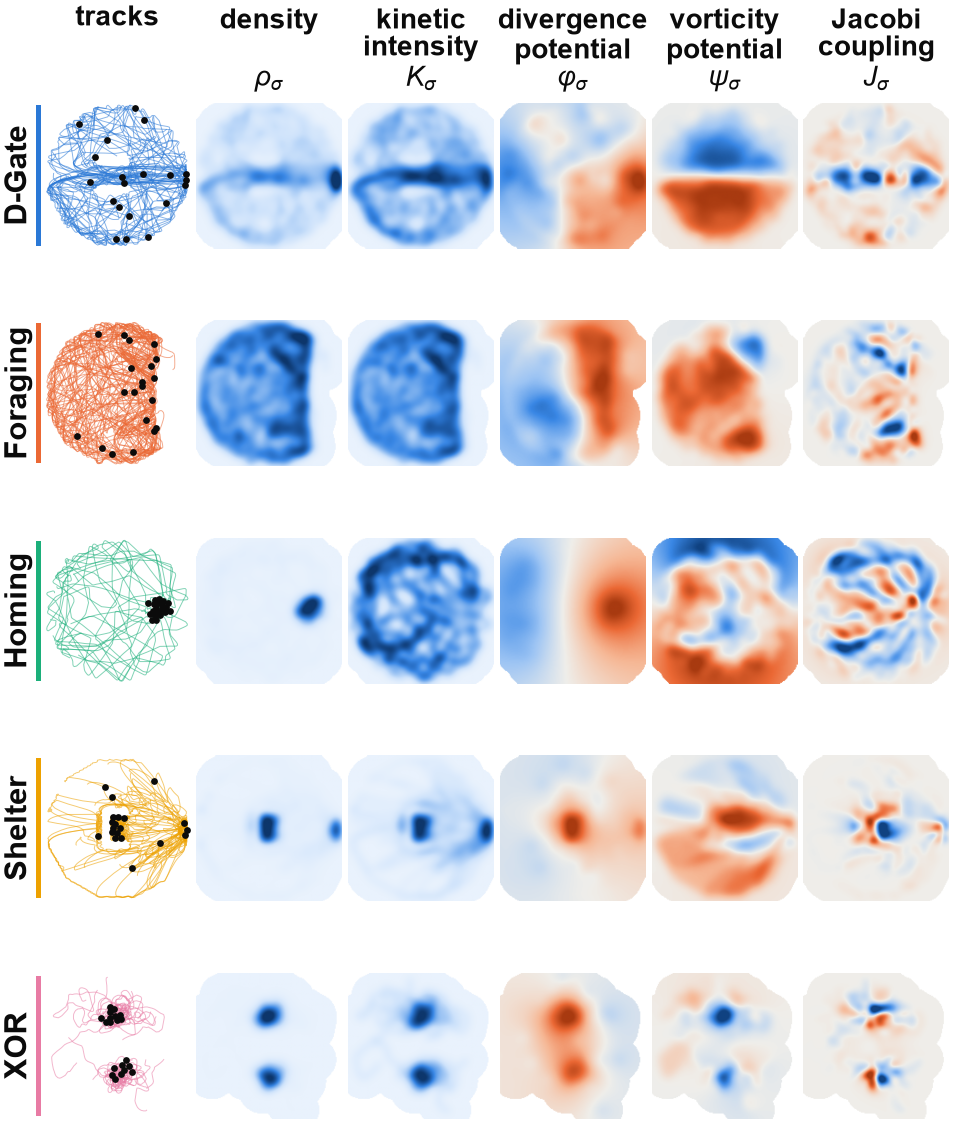

In [9]:
M.fig_pair_separation(); show("fig_pair_separation", 860)
M.fig_fields(); show("fig_fields", 780)

## 6. Attribution & Field Ablation (Figures 9 & 10)

* **Figure 9 (`fig_attribution`)** — Differentiable back-propagation of $\mathrm{SW}_1(\psi_{\sigma_3})$ between D-Gate and Foraging: extended persistence concentrates on the two rotation centers and endpoints of the gate corridor (`14%` of arena holds half the mean map), while quantile values scatter over ordinary points.
* **Figure 10 (`fig_ablation`)** — Eleven field combinations across `990` settings (`Top-1..Top-10` $\times$ `99`): combining all five fields maximizes error-free settings (`440/990`) and preserves monotone cluster counts.

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_attribution.pdf


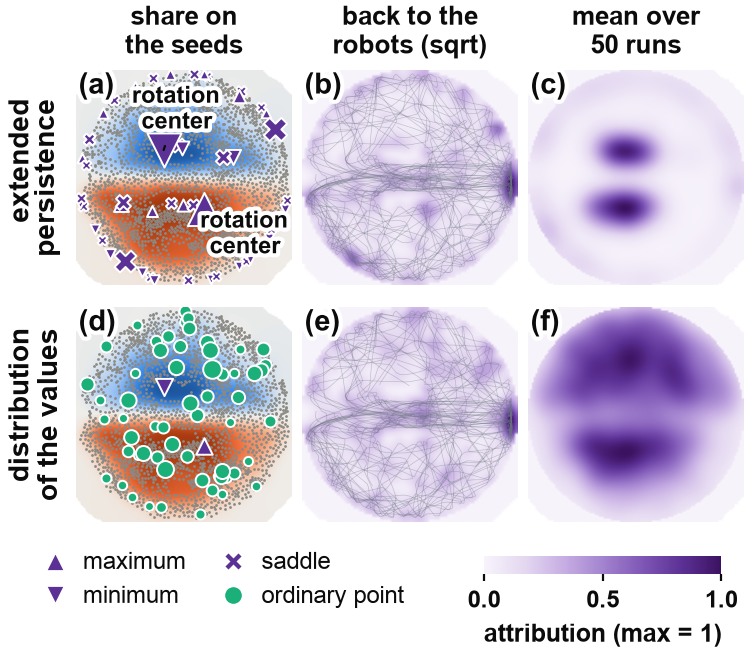

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_ablation.pdf


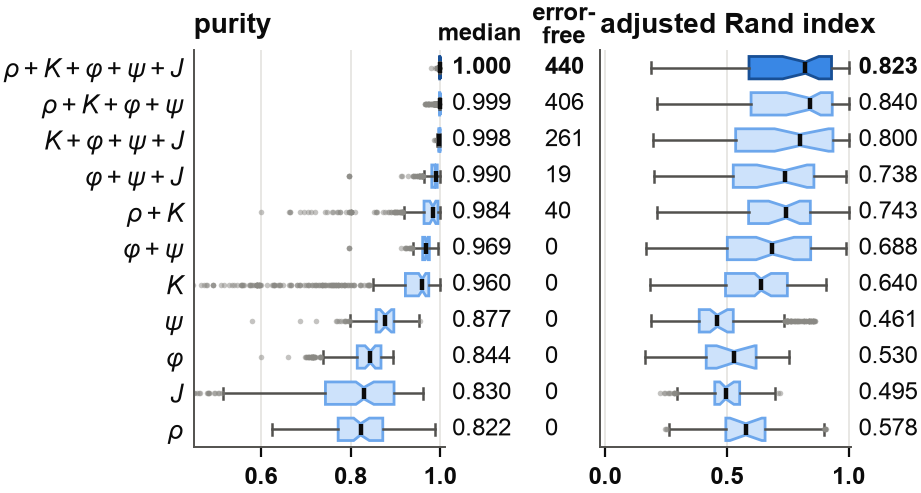

In [10]:
M.fig_attribution(); show("fig_attribution", 820)
M.fig_ablation(); show("fig_ablation", 860)

## 7. Appendix Figures & Auxiliary Diagnostics

* `fig_scales` & `figA_uncapped` — Shelter across $\sigma_1 \dots \sigma_4$ vs uncapped smooth collapse.
* `figA_merge` — Late-settling XOR Aggregation trajectories overlapping Shelter.
* `fig_pipeline_one`, `fig_pipeline_all`, `fig_resolution_compact`, `fig_fusion_sequence`, `figA_pooled`, `figA_cap` — Supporting pipeline views and pooled contingency heatmaps.

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_scales.pdf


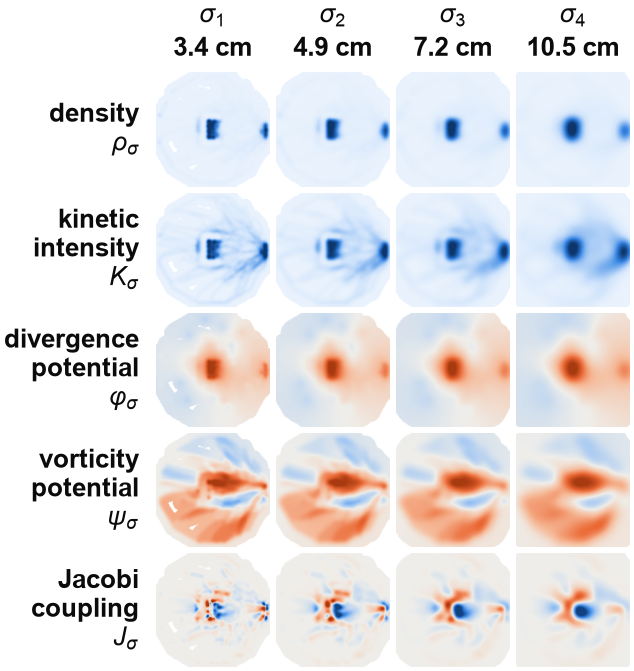

saved /home/ndinga/Documents/paper_topological_kinematics/figures/figA_uncapped.pdf


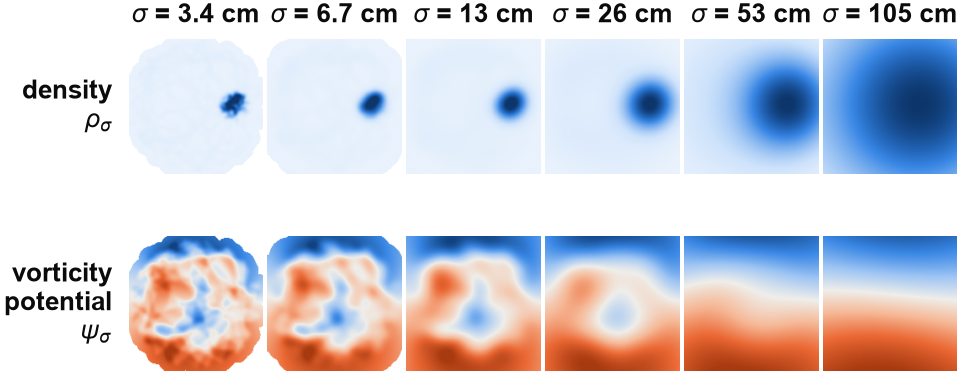

saved /home/ndinga/Documents/paper_topological_kinematics/figures/figA_merge.pdf


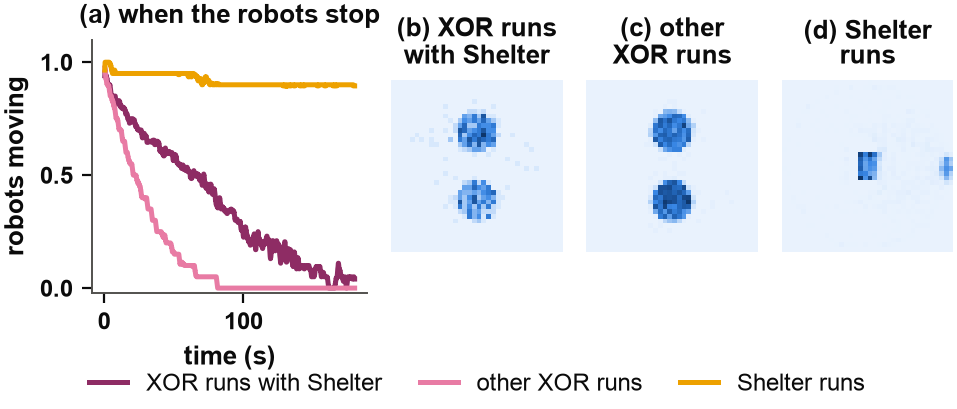

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_resolution_compact.pdf


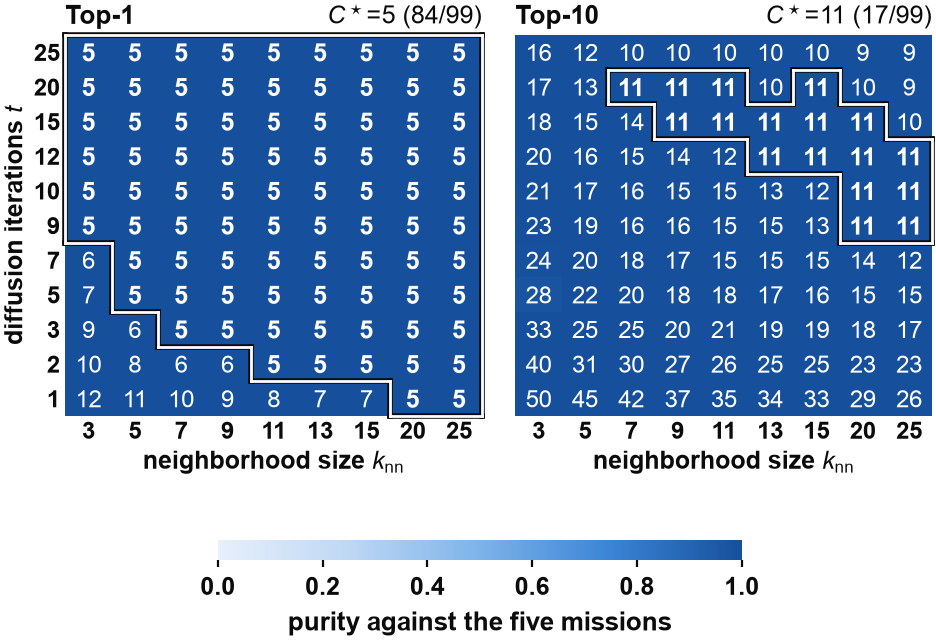

saved /home/ndinga/Documents/paper_topological_kinematics/figures/fig_fusion_sequence.pdf


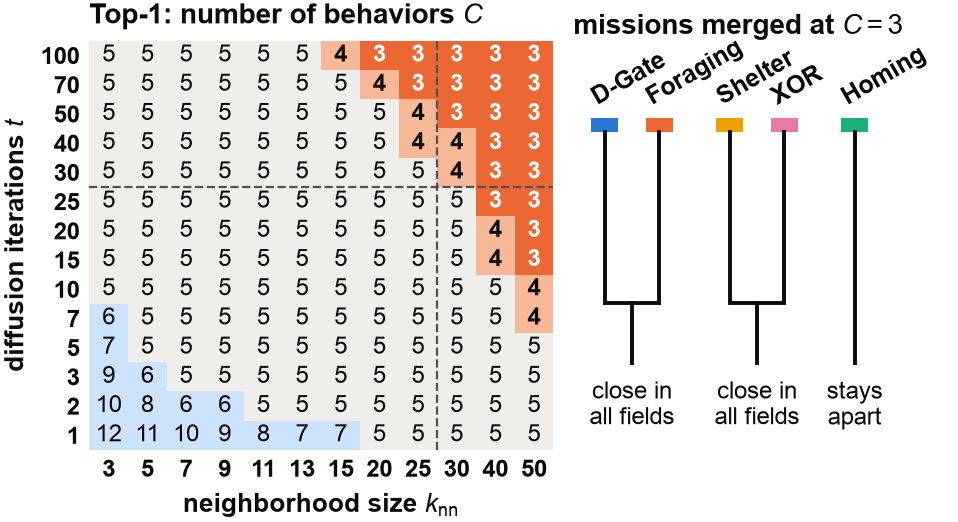

In [11]:
M.fig_scales(); show("fig_scales", 700)
M.fig_uncapped(); show("figA_uncapped", 880)
M.fig_merge(); show("figA_merge", 850)
M.fig_resolution_compact(); show("fig_resolution_compact", 850)
M.fig_fusion_sequence(); show("fig_fusion_sequence", 850)

## 8. Regenerating Verified Manuscript Macros (`manuscript/numbers.tex`)

In [12]:
res = subprocess.run([sys.executable, str(ROOT / "analysis/make_numbers.py")], capture_output=True, text=True, check=True)
print(res.stdout[-1500:] if len(res.stdout) > 1500 else res.stdout)

832 numbers written; tables: ['attribution_pairs.tex', 'baselines.tex', 'baselines_top1.tex', 'designs.tex', 'parameter_study.tex', 'settings.tex', 'study.tex', 't10.tex', 'taxonomy.tex', 'variants.tex']
claims of the text checked on the results: 136 of 136 hold

